In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

sys.path.insert(0, str(PROJECT_DIR))

from src.irrigation_env import SmartIrrigationEnv

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(
    DATA_DIR / "weather_with_et0.csv",
    parse_dates=["time"]
)

df_2020 = (
    df[df["time"].dt.year == 2020]
    .sort_values("time")
    .reset_index(drop=True)
)

print("Weather records:", len(df_2020))
print("Environment ready!")

Weather records: 153
Environment ready!


In [2]:
# ==========================================
# Random vs Threshold-Based Agent
# ==========================================

def run_agent(strategy, seed=42):

    env = SmartIrrigationEnv(df_2020)

    observation, info = env.reset(seed=seed)
    env.action_space.seed(seed)

    records = []
    done = False

    while not done:

        moisture_before = env.soil.get_soil_moisture()

        if strategy == "random":
            action = env.action_space.sample()

        elif strategy == "threshold":
            action = (
                3 if moisture_before < 0.25 else 0
            )

        else:
            raise ValueError("Unknown strategy")

        observation, reward, terminated, truncated, info = (
            env.step(action)
        )

        records.append({
            "day": info["day"],
            "strategy": strategy,
            "soil_moisture": info["soil_moisture"],
            "irrigation_mm": info["irrigation_mm"],
            "reward": reward,
            "drainage_mm": info["drainage_mm"],
            "stress_factor": info["stress_factor"]
        })

        done = terminated or truncated

    env.close()

    return pd.DataFrame(records)


random_results = run_agent("random")
threshold_results = run_agent("threshold")

print("Both simulations completed!")

display(random_results.head())
display(threshold_results.head())

Both simulations completed!


,day,strategy,soil_moisture,irrigation_mm,reward,drainage_mm,stress_factor
0,1,random,0.263318,0.0,0.800000,0.0,0.800000
1,2,random,0.280414,8.0,0.508786,0.0,0.908786
2,3,random,0.292449,5.0,0.750000,0.0,1.000000
3,4,random,0.287096,2.0,0.876327,0.0,0.976327
4,5,random,0.284431,2.0,0.841973,0.0,0.941973


,day,strategy,soil_moisture,irrigation_mm,reward,drainage_mm,stress_factor
0,1,threshold,0.263318,0.0,0.800000,0.0,0.800000
1,2,threshold,0.265107,0.0,0.802120,0.0,0.802120
2,3,threshold,0.268441,0.0,0.832711,0.0,0.832711
3,4,threshold,0.260877,0.0,0.789606,0.0,0.789606
4,5,threshold,0.255680,0.0,0.740511,0.0,0.740511


In [3]:
# ==========================================
# Strategy Performance Comparison
# ==========================================

def calculate_metrics(data):

    return {
        "Total Irrigation (mm)": data["irrigation_mm"].sum(),
        "Average Soil Moisture": data["soil_moisture"].mean(),
        "Target Days (%)": (
            data["soil_moisture"]
            .between(0.25, 0.30)
            .mean() * 100
        ),
        "Total Drainage (mm)": data["drainage_mm"].sum(),
        "Total Reward": data["reward"].sum()
    }


comparison = pd.DataFrame({
    "Random Agent": calculate_metrics(random_results),
    "Threshold Agent": calculate_metrics(threshold_results)
}).T

display(comparison.round(3))

comparison.to_csv(
    RESULTS_DIR / "week3_agent_comparison.csv"
)

,Total Irrigation (mm),Average Soil Moisture,Target Days (%),Total Drainage (mm),Total Reward
Random Agent,608.0,0.281,89.542,158.670,87.749
Threshold Agent,360.0,0.259,70.588,33.323,51.443


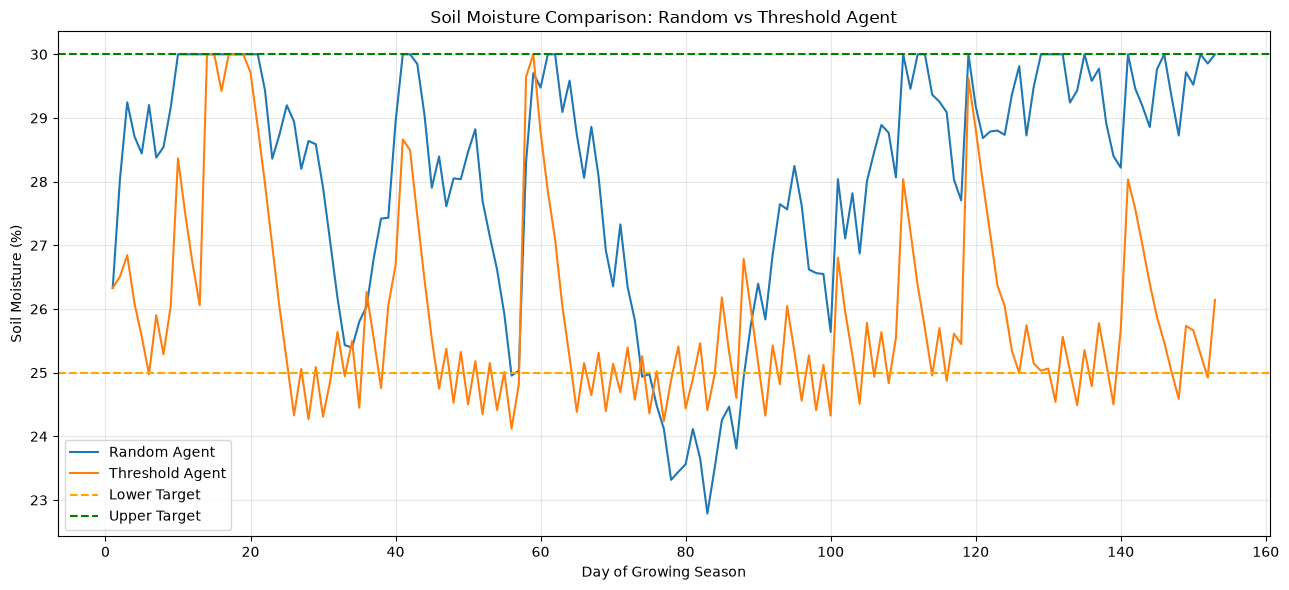

In [4]:
# ==========================================
# Soil Moisture Comparison
# ==========================================

plt.figure(figsize=(13, 6))

plt.plot(
    random_results["day"],
    random_results["soil_moisture"] * 100,
    label="Random Agent",
    linewidth=1.5
)

plt.plot(
    threshold_results["day"],
    threshold_results["soil_moisture"] * 100,
    label="Threshold Agent",
    linewidth=1.5
)

plt.axhline(
    25,
    linestyle="--",
    color="orange",
    label="Lower Target"
)

plt.axhline(
    30,
    linestyle="--",
    color="green",
    label="Upper Target"
)

plt.title(
    "Soil Moisture Comparison: Random vs Threshold Agent"
)

plt.xlabel("Day of Growing Season")
plt.ylabel("Soil Moisture (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "week3_agent_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# ==========================================
# Multiple Random Agent Evaluations
# ==========================================

random_experiments = []

for seed in range(20):

    result = run_agent(
        strategy="random",
        seed=seed
    )

    metrics = calculate_metrics(result)

    metrics["seed"] = seed

    random_experiments.append(metrics)

random_evaluation = pd.DataFrame(
    random_experiments
)

print("RANDOM AGENT - 20 RUNS")
print("=" * 50)

summary = random_evaluation.drop(
    columns=["seed"]
).agg(["mean", "std", "min", "max"])

display(summary.round(3))

random_evaluation.to_csv(
    RESULTS_DIR / "random_agent_20_runs.csv",
    index=False
)

RANDOM AGENT - 20 RUNS


,Total Irrigation (mm),Average Soil Moisture,Target Days (%),Total Drainage (mm),Total Reward
mean,596.250,0.278,89.412,162.196,84.643
std,34.511,0.003,5.350,24.431,12.305
min,523.000,0.272,79.085,116.866,63.234
max,678.000,0.283,95.425,219.456,99.255


In [6]:
# ==========================================
# Train / Validation / Test Split
# ==========================================

train_df = df[
    df["time"].dt.year.between(2020, 2023)
].copy()

val_df = df[
    df["time"].dt.year == 2024
].copy()

test_df = df[
    df["time"].dt.year == 2025
].copy()

print("DATASET SPLIT")
print("=" * 45)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

assert len(train_df) == 612
assert len(val_df) == 153
assert len(test_df) == 153

train_df.to_csv(
    DATA_DIR / "train_weather.csv",
    index=False
)

val_df.to_csv(
    DATA_DIR / "val_weather.csv",
    index=False
)

test_df.to_csv(
    DATA_DIR / "test_weather.csv",
    index=False
)

print("\nDatasets saved successfully!")

DATASET SPLIT
Training records: 612
Validation records: 153
Testing records: 153

Datasets saved successfully!
